In [1]:
from multiprocessing import Process, Queue
import functools
from typing import Callable, Optional
import fastplotlib as fpl
import numpy as np

fastplotlib version from git (0.4.0) and __version__ (0.5.0) don't match.
wgpu version from git (0.15.3) and __version__ (0.22.1) don't match.
rendercanvas version from git (2.0.0) and __version__ (2.0.1) don't match.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅,AMD Radeon 780M (RADV GFX1103_R1),IntegratedGPU,Vulkan,Mesa 24.2.8
✅ (default),NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
✅,NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
❗ limited,"llvmpipe (LLVM 19.1.0, 256 bits)",CPU,Vulkan,Mesa 24.2.8 (LLVM 19.1.0)
❌,"AMD Radeon 780M (radeonsi, gfx1103_r1, LLVM 19.1.0, DRM 3.59, 6.12.4-200.fc41.x86_64)",Unknown,OpenGL,4.6 (Core Profile) Mesa 24.2.8


pygfx version from git (0.6.0) and __version__ (0.9.0) don't match.
Incompatible version of wgpu:
    Detected 0.15.3.post134+g6b77f99, need >=(0, 19, 0), <(0, 23, 0).
    To update, use e.g. `pip install -U wgpu`.
Incompatible version of pylinalg:
    Detected 0.6.3, need >=(0, 6, 7), <(0, 7, 0).
    To update, use e.g. `pip install -U pylinalg`.


In [2]:
def dispatch(queue: Optional[mp.Queue] = None):
    """
    Decorator that immediately dispatches a function to run in a separate process.
    The decorated function starts the process and returns immediately without waiting.
    
    Args:
        queue: Optional multiprocessing Queue for communication.
               The queue is passed as the first argument to the decorated function.
    
    Returns:
        Decorator function that returns the started Process object
    """
    def decorator(func: Callable) -> Callable:
        @functools.wraps(func)
        def wrapper(*args, **kwargs):
            def target_function():
                # If queue is provided, pass it as first argument
                if queue is not None:
                    func(queue, *args, **kwargs)
                else:
                    func(*args, **kwargs)
            
            # Create and start the process
            process = mp.Process(target=target_function)
            process.start()
            
            # Return the process object immediately (don't wait)
            return process
        
        return wrapper
    return decorator

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
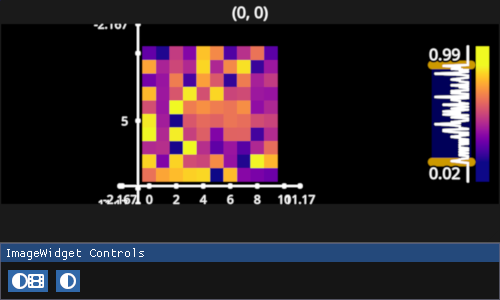

In [3]:
iw = fpl.ImageWidget(np.random.rand(10, 10))
iw.show()

In [4]:
q = mp.Queue(maxsize=1)

In [5]:
def update(fig):
    if q.empty():
        return
    title, data = q.get()
    fig[0, 0].title = str(title)
    fig[0, 0].graphics[0].data = data

In [6]:
iw.figure.add_animations(update)

In [7]:
@dispatch(q)
def compute(queue: mp.Queue, val):
    for i in range(10_000):
        out = np.random.rand(10, 10) * val
        
        while not q.empty:
            queue.get_nowait()
            
        queue.put((i, out))

In [2]:
import numpy as np

In [3]:
val = 5

for i in range(10_000):
    out = np.random.rand(10, 10) * val
    
    # while not q.empty:
    #     queue.get_nowait()
        
    # queue.put((i, out))

In [8]:
compute(5)

<Process name='Process-1' pid=74545 parent=74489 started>